In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [ ]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [ ]:
df = pd.read_csv("weatherHistory.csv")

In [ ]:
df.shape

(30711, 12)

In [ ]:
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [ ]:
df.dtypes

,0
Formatted Date,object
Summary,object
Precip Type,object
Temperature (C),float64
Apparent Temperature (C),float64
Humidity,float64
Wind Speed (km/h),float64
Wind Bearing (degrees),float64
Visibility (km),float64
Loud Cover,float64


In [ ]:
df.columns.tolist()

['Formatted Date',
 'Summary',
 'Precip Type',
 'Temperature (C)',
 'Apparent Temperature (C)',
 'Humidity',
 'Wind Speed (km/h)',
 'Wind Bearing (degrees)',
 'Visibility (km)',
 'Loud Cover',
 'Pressure (millibars)',
 'Daily Summary']

In [ ]:
df.describe()

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars)
count,30711.000000,30711.000000,30711.000000,30711.000000,30711.000000,30711.000000,30710.0,30710.000000
mean,11.699722,10.557827,0.718858,10.844690,190.244961,10.079734,0.0,1000.698819
std,9.720464,10.845200,0.192263,6.935478,106.223321,3.773028,0.0,129.262036
min,-16.666667,-24.233333,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,4.075000,1.847222,0.590000,5.787950,120.000000,9.676100,0.0,1011.880000
50%,11.216667,11.216667,0.770000,9.869300,187.000000,9.982000,0.0,1016.720000
75%,18.838889,18.838889,0.870000,14.232400,290.000000,11.270000,0.0,1021.900000
max,39.905556,38.377778,1.000000,63.852600,359.000000,16.100000,0.0,1046.380000


In [ ]:
df['Summary'].value_counts()

,count
Summary,
Partly Cloudy,10440
Mostly Cloudy,7978
Overcast,5185
Clear,4371
Foggy,2157
Breezy and Mostly Cloudy,175
Breezy and Partly Cloudy,146
Breezy and Overcast,126
Windy and Partly Cloudy,33


In [ ]:
df['Precip Type'].value_counts(dropna=False)

,count
Precip Type,
rain,26929
snow,3782


In [ ]:
df.isnull().sum()

,0
Formatted Date,0
Summary,0
Precip Type,0
Temperature (C),0
Apparent Temperature (C),0
Humidity,0
Wind Speed (km/h),0
Wind Bearing (degrees),0
Visibility (km),0
Loud Cover,1


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
(df['Loud Cover'] == 0).mean()

np.float64(0.9999674383771288)

In [ ]:
(df['Pressure (millibars)'] == 0).sum()

np.int64(502)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

In [ ]:
df['Precip Type'] = df['Precip Type'].fillna('none')

In [ ]:
df = df.drop(columns=['Loud Cover'])

In [ ]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], utc=True)

In [ ]:
df = df.sort_values('Formatted Date').reset_index(drop=True)

In [ ]:
df['Pressure (millibars)'] = df['Pressure (millibars)'].replace(0, np.nan)

In [ ]:
df['Pressure (millibars)'] = df['Pressure (millibars)'].fillna(df['Pressure (millibars)'].median())

In [ ]:
df['Year'] = df['Formatted Date'].dt.year

In [ ]:
df['Month'] = df['Formatted Date'].dt.month

In [ ]:
df['Hour'] = df['Formatted Date'].dt.hour

In [ ]:
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

In [ ]:
df['Season'] = df['Month'].apply(month_to_season)

In [ ]:
df['Temp Diff'] = df['Temperature (C)'] - df['Apparent Temperature (C)']

In [ ]:
df['Is Daytime'] = df['Hour'].between(6, 18)

In [ ]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [ ]:
low, high = iqr_bounds(df['Wind Speed (km/h)'])
outlier_share = ((df['Wind Speed (km/h)'] < low) | (df['Wind Speed (km/h)'] > high)).mean()
outlier_share

np.float64(0.02927289896128423)

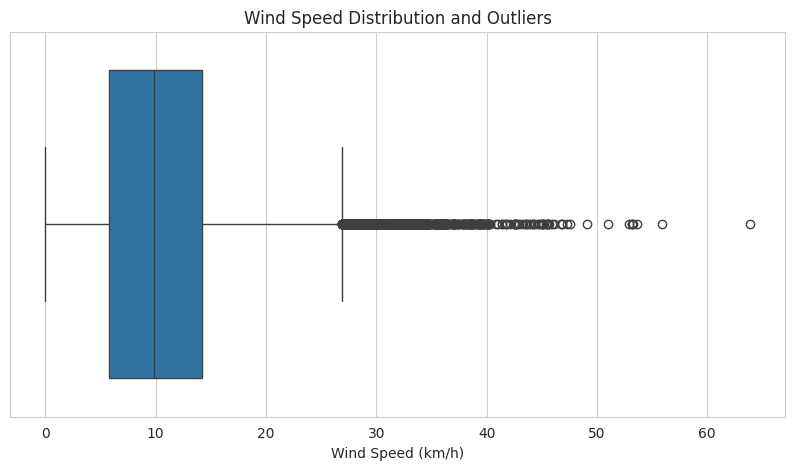

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(x=df['Wind Speed (km/h)'], ax=ax)
ax.set_title('Wind Speed Distribution and Outliers')
plt.show()

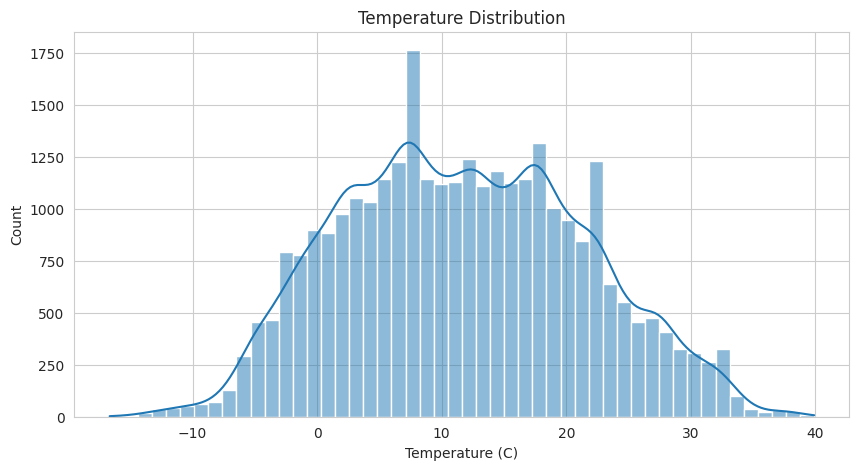

In [ ]:
fig, ax = plt.subplots()
sns.histplot(df['Temperature (C)'], bins=50, kde=True, ax=ax)
ax.set_title('Temperature Distribution')
plt.show()

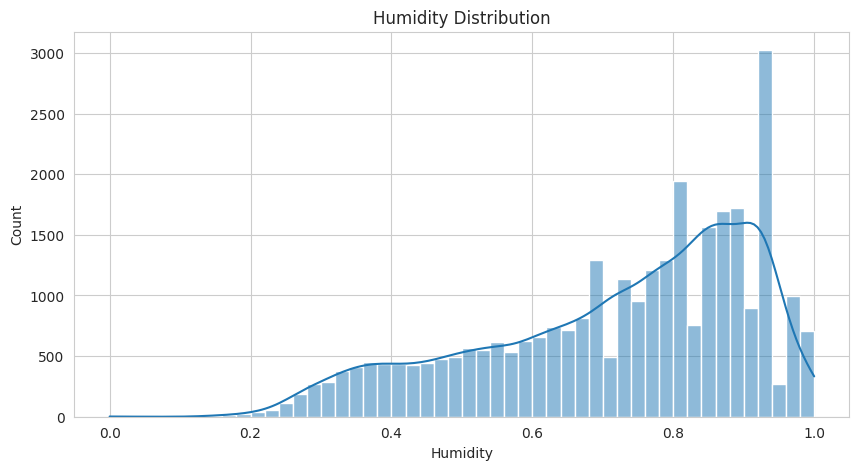

In [ ]:
fig, ax = plt.subplots()
sns.histplot(df['Humidity'], bins=50, kde=True, ax=ax)
ax.set_title('Humidity Distribution')
plt.show()

In [ ]:
numeric_cols = ['Temperature (C)', 'Apparent Temperature (C)', 'Humidity',
                 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)',
                 'Pressure (millibars)']
corr = df[numeric_cols].corr()
corr

,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars)
Temperature (C),1.000000,0.992257,-0.663470,0.012099,0.018921,0.343592,-0.360350
Apparent Temperature (C),0.992257,1.000000,-0.633119,-0.059092,0.015842,0.332741,-0.337157
Humidity,-0.663470,-0.633119,1.000000,-0.221307,0.019799,-0.291853,0.112793
Wind Speed (km/h),0.012099,-0.059092,-0.221307,1.000000,0.087647,0.115990,-0.248493
Wind Bearing (degrees),0.018921,0.015842,0.019799,0.087647,1.000000,0.048961,-0.067894
Visibility (km),0.343592,0.332741,-0.291853,0.115990,0.048961,1.000000,-0.222344
Pressure (millibars),-0.360350,-0.337157,0.112793,-0.248493,-0.067894,-0.222344,1.000000


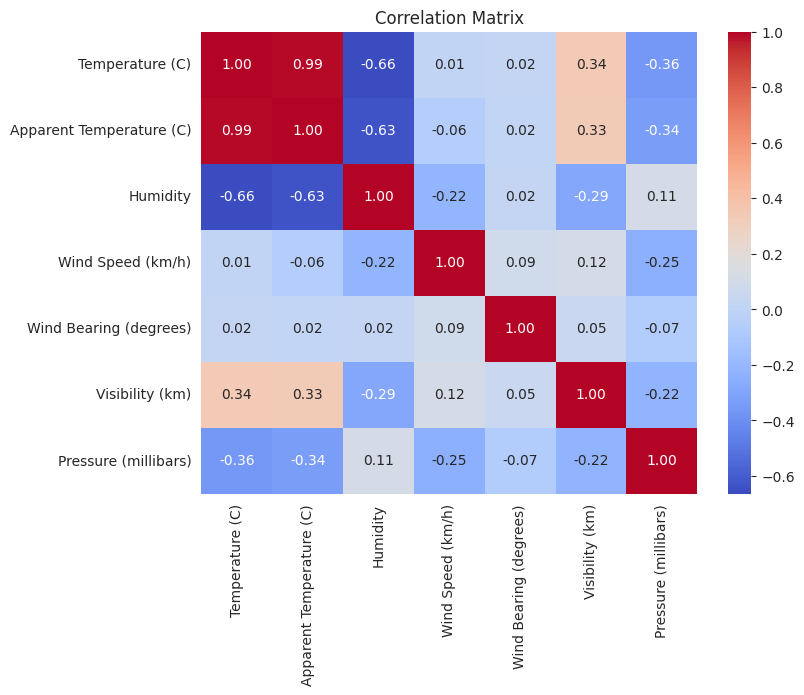

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Correlation Matrix')
plt.show()

In [ ]:
monthly_avg = df.groupby('Month')['Temperature (C)'].mean()
monthly_avg

,Temperature (C)
Month,
1,0.714860
2,2.697135
3,6.706431
4,12.838113
5,16.796807
6,20.916534
7,23.089652
8,22.115418
9,16.160165


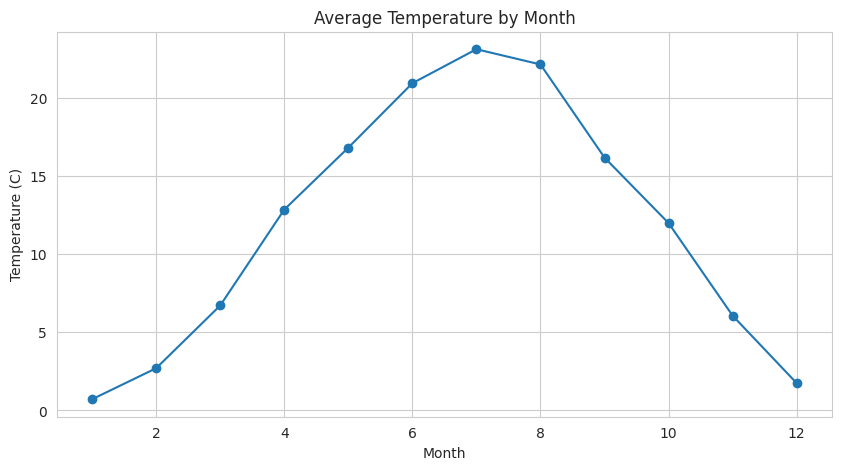

In [ ]:
fig, ax = plt.subplots()
monthly_avg.plot(kind='line', marker='o', ax=ax)
ax.set_title('Average Temperature by Month')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (C)')
plt.show()

In [ ]:
yearly_avg = df.groupby('Year')['Temperature (C)'].mean()
yearly_avg

,Temperature (C)
Year,
2005,0.577778
2006,11.215225
2007,12.134677
2008,12.161819
2009,10.807997
2010,23.933102


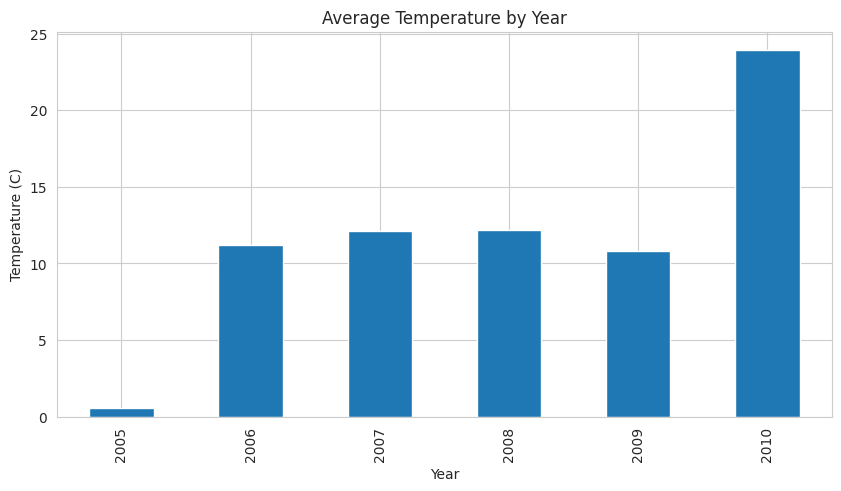

In [ ]:
fig, ax = plt.subplots()
yearly_avg.plot(kind='bar', ax=ax)
ax.set_title('Average Temperature by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Temperature (C)')
plt.show()

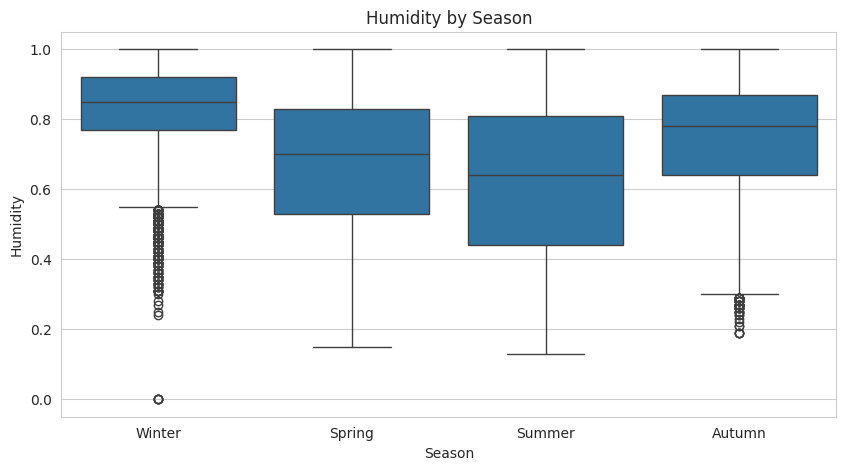

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x='Season', y='Humidity', ax=ax)
ax.set_title('Humidity by Season')
plt.show()

In [ ]:
r_value, p_value = stats.pearsonr(df['Temperature (C)'], df['Humidity'])
r_value, p_value

(np.float64(-0.663470213928346), np.float64(0.0))

In [ ]:
summer = df[df['Season'] == 'Summer']['Humidity']
winter = df[df['Season'] == 'Winter']['Humidity']
t_stat, t_p = stats.ttest_ind(summer, winter, equal_var=False)
t_stat, t_p

(np.float64(-74.73719089178348), np.float64(0.0))

In [ ]:
season_groups = [g['Wind Speed (km/h)'].values for _, g in df.groupby('Season')]
f_stat, anova_p = stats.f_oneway(*season_groups)
f_stat, anova_p

(np.float64(157.64370871379322), np.float64(2.1089139959899563e-101))

In [ ]:
features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
            'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)']
X = df[features]
y = df['Apparent Temperature (C)']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
y_pred = lr_model.predict(X_test_scaled)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
mae, rmse, r2

(0.8468437777132067, 1.0801738008189607, 0.9899727838843265)

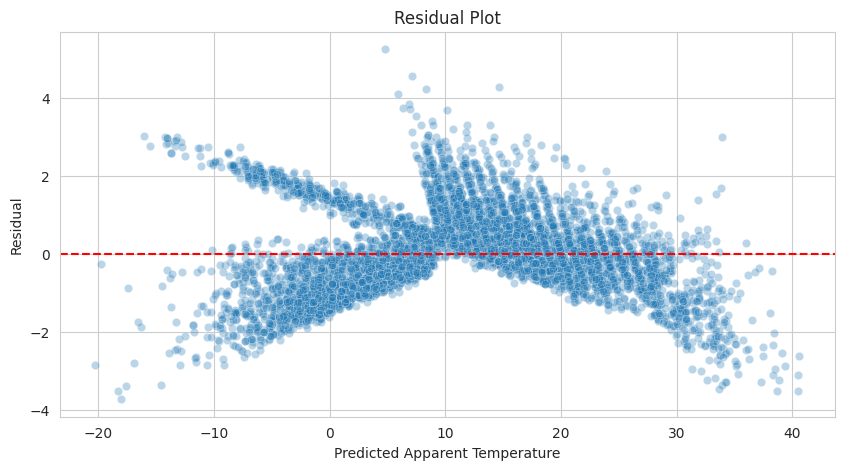

In [ ]:
fig, ax = plt.subplots()
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3, ax=ax)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Predicted Apparent Temperature')
ax.set_ylabel('Residual')
ax.set_title('Residual Plot')
plt.show()

In [ ]:
coef_table = pd.Series(lr_model.coef_, index=features).sort_values()
coef_table

,0
Wind Speed (km/h),-0.701438
Visibility (km),0.013006
Wind Bearing (degrees),0.026119
Pressure (millibars),0.099684
Humidity,0.244841
Temperature (C),10.975652


In [ ]:
clf_df = df[df['Precip Type'] != 'none'].copy()
clf_df['Is Rain'] = (clf_df['Precip Type'] == 'rain').astype(int)
clf_df['Is Rain'].value_counts()

,count
Is Rain,
1,26929
0,3782


In [ ]:
clf_features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Pressure (millibars)']
Xc = clf_df[clf_features]
yc = clf_df['Is Rain']

In [ ]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)

In [ ]:
clf_scaler = StandardScaler()
Xc_train_scaled = clf_scaler.fit_transform(Xc_train)
Xc_test_scaled = clf_scaler.transform(Xc_test)

In [ ]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(Xc_train_scaled, yc_train)

LogisticRegression(max_iter=1000)

In [ ]:
yc_pred = log_model.predict(Xc_test_scaled)

In [ ]:
acc = accuracy_score(yc_test, yc_pred)
prec = precision_score(yc_test, yc_pred)
rec = recall_score(yc_test, yc_pred)
f1 = f1_score(yc_test, yc_pred)
acc, prec, rec, f1

(0.9957675402897607,
 0.9972175848636616,
 0.9979580471505476,
 0.9975876786045649)

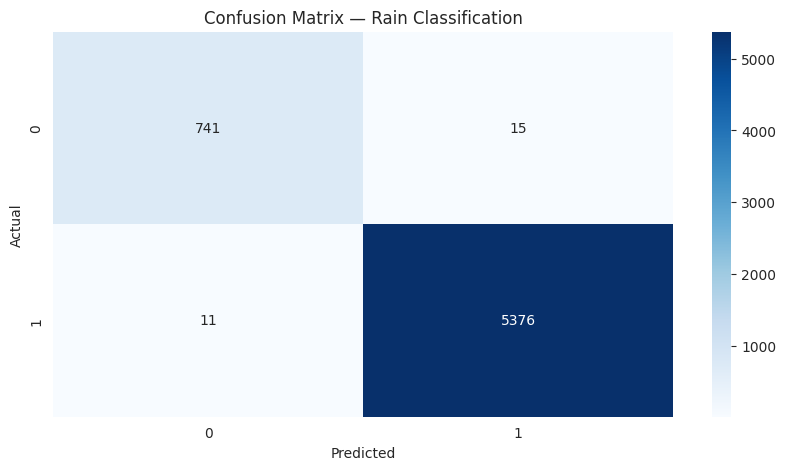

In [ ]:
cm = confusion_matrix(yc_test, yc_pred)
fig, ax = plt.subplots()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix — Rain Classification')
plt.show()

In [ ]:
cluster_features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Pressure (millibars)']
Xk = StandardScaler().fit_transform(df[cluster_features])

In [ ]:
inertias = []
k_range = range(2, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(Xk)
    inertias.append(km.inertia_)

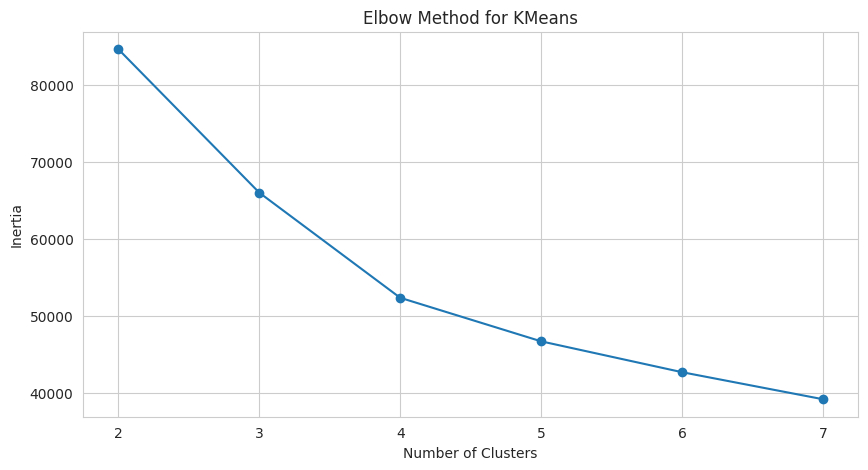

In [ ]:
fig, ax = plt.subplots()
ax.plot(list(k_range), inertias, marker='o')
ax.set_xlabel('Number of Clusters')
ax.set_ylabel('Inertia')
ax.set_title('Elbow Method for KMeans')
plt.show()

In [ ]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(Xk)

In [ ]:
silhouette_score(Xk, df['Cluster'])

np.float64(0.2842161964291782)

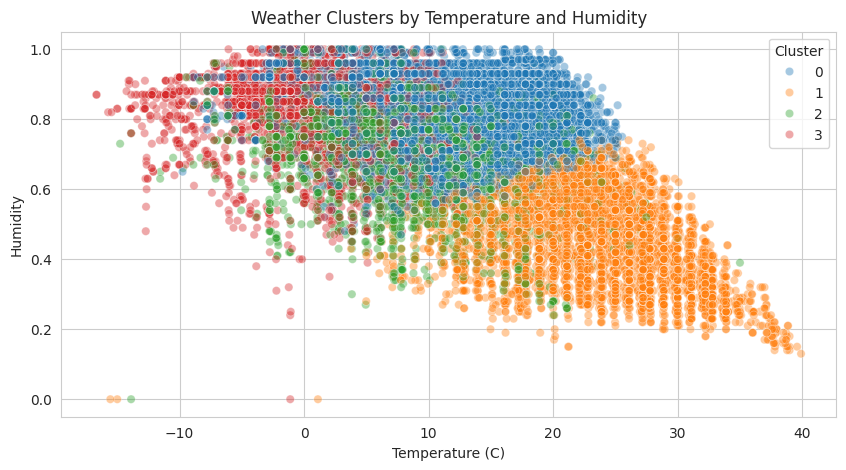

In [ ]:
fig, ax = plt.subplots()
sns.scatterplot(data=df, x='Temperature (C)', y='Humidity', hue='Cluster', palette='tab10', alpha=0.4, ax=ax)
ax.set_title('Weather Clusters by Temperature and Humidity')
plt.show()

In [ ]:
pca = PCA(n_components=len(cluster_features))
pca.fit(Xk)
pca.explained_variance_ratio_

array([0.46899286, 0.26462839, 0.20816804, 0.05821071])

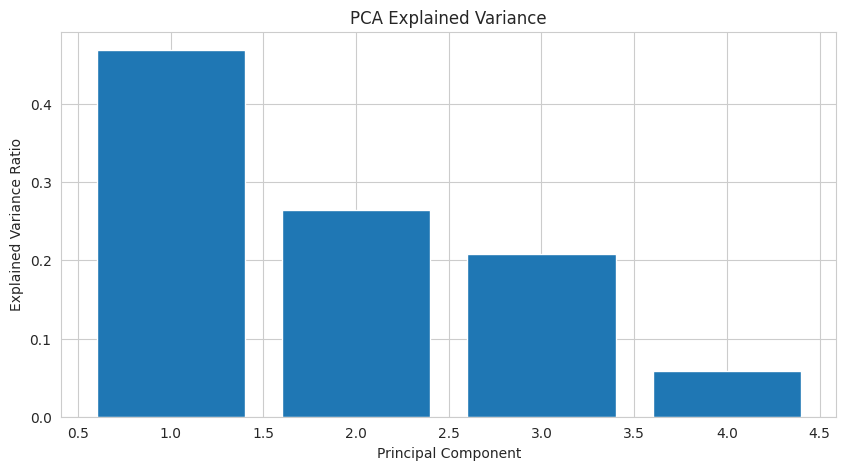

In [ ]:
fig, ax = plt.subplots()
ax.bar(range(1, len(cluster_features) + 1), pca.explained_variance_ratio_)
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('PCA Explained Variance')
plt.show()

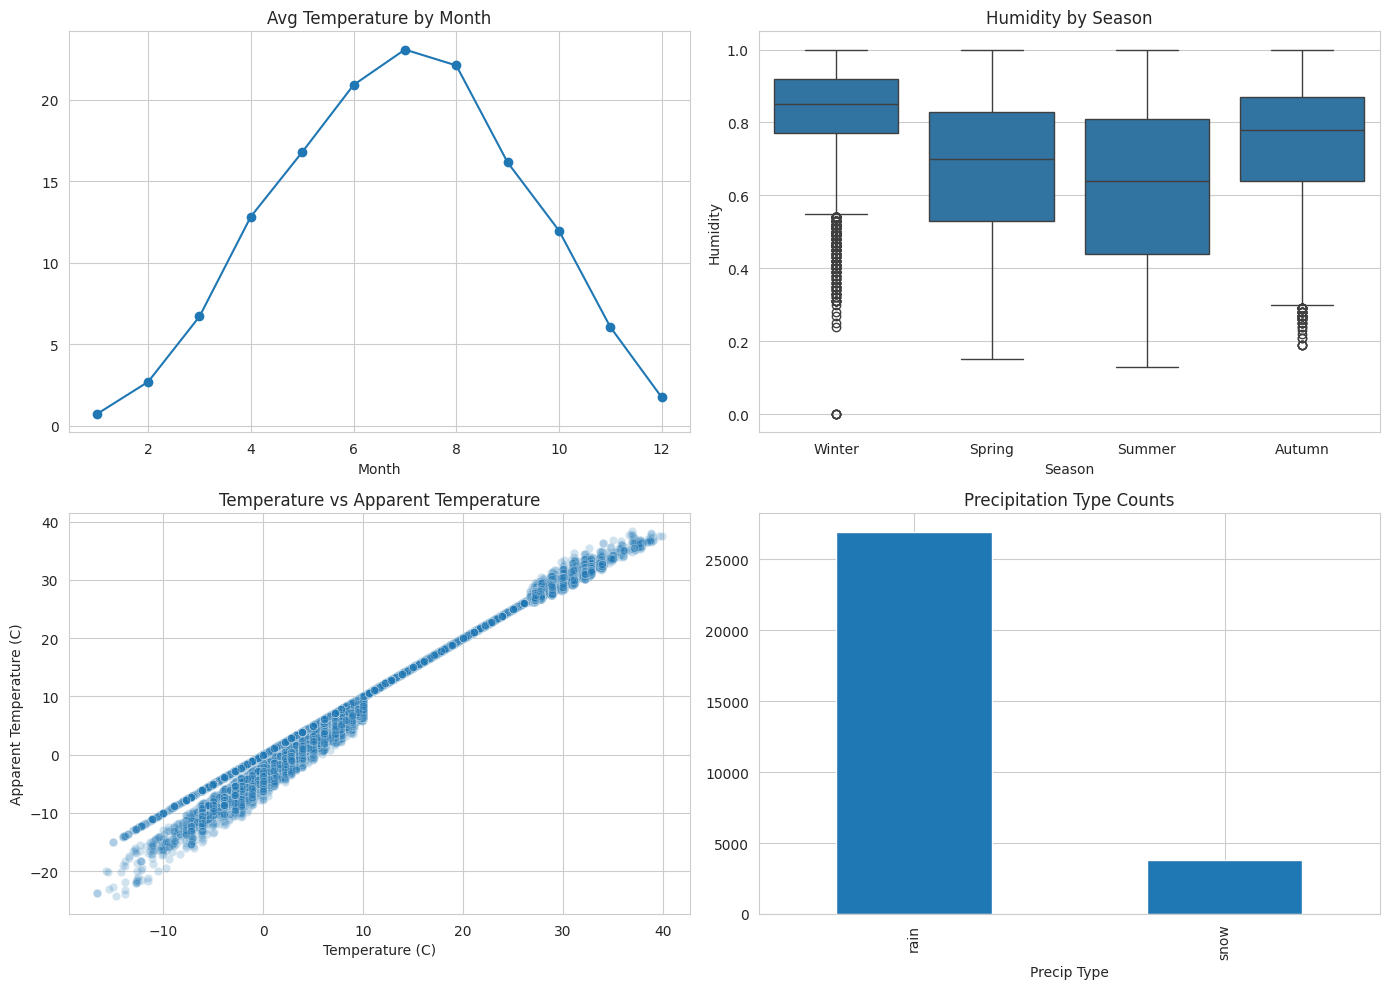

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

monthly_avg.plot(kind='line', marker='o', ax=axes[0, 0])
axes[0, 0].set_title('Avg Temperature by Month')

sns.boxplot(data=df, x='Season', y='Humidity', ax=axes[0, 1])
axes[0, 1].set_title('Humidity by Season')

sns.scatterplot(data=df, x='Temperature (C)', y='Apparent Temperature (C)', alpha=0.2, ax=axes[1, 0])
axes[1, 0].set_title('Temperature vs Apparent Temperature')

df['Precip Type'].value_counts().plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Precipitation Type Counts')

plt.tight_layout()
plt.show()

In [ ]:
summary_points = {
    'Regression R2 (Apparent Temperature)': r2,
    'Regression RMSE': rmse,
    'Classification Accuracy (Rain)': acc,
    'Classification F1 (Rain)': f1,
    'Best Silhouette Score': silhouette_score(Xk, df['Cluster'])
}
pd.Series(summary_points)

,0
Regression R2 (Apparent Temperature),0.989973
Regression RMSE,1.080174
Classification Accuracy (Rain),0.995768
Classification F1 (Rain),0.997588
Best Silhouette Score,0.284216
